In [31]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
pratyushpuri_ai_vs_human_content_detection_1000_record_in_2025_path = kagglehub.dataset_download('pratyushpuri/ai-vs-human-content-detection-1000-record-in-2025')

print('Data source import complete.')

Data source import complete.


In [32]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

#Just error check (work-in-progress)
#import os, pandas as pd
#if os.path.exists("/kaggle/input"):
#  data_path = "/kaggle/input/ai-vs-human-content-detection-1000-record-in-2025"
#else:
#  import kagglehub
#  data_path = kagglehub.dataset_download('pratyushpuri/ai-vs-human-content-detection-1000-record-in-2025')
#  print("Dataset path:", data_path)
#df = pd.read_csv(os.path.join(data_path, "ai-vs-human-content-detection-1000-record-in-2025"))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [33]:
# Ashwin Vinod
# fixed preprocessing for split datasets
def one_hot_encode(df, column):
  unique = df[column].unique() # find all unique values in the dataset
  unique.sort() # sort them
  index = df.columns.get_loc(column) # get the index of the column

  for val in unique: # loop through the unique values
    name = column + "_" + str(val) # append column and _val
    df.insert(index, name, 0) # insert it
    #df.insert(index,name,(df[column] == val).astype(int))
    df.loc[df[column] == val, name] = 1 # boolean mask to set the column value to 1 where applicable
    index += 1

  return df.drop(column, axis=1) # drop the original column

def min_max(series):
  return (series - series.min()) / (series.max() - series.min())

def z_score(series):
  return (series - series.mean()) / series.std()

# Logan Caraway
# preprocessing for non-text data
# irrelevant for now since we are not only using text content
def preprocess(df):
  counts = ['word_count', 'character_count', 'sentence_count', 'grammar_errors']
  bounded = ['lexical_diversity', 'passive_voice_ratio', 'punctuation_ratio', 'burstiness', 'sentiment_score']
  continuous = ['flesch_reading_ease', 'gunning_fog_index', 'predictability_score', 'avg_sentence_length', 'avg_word_length']

  # special cases

  if 'sentiment_score' in df.columns:
    df['sentiment_score'] = pd.to_numeric(df['sentiment_score'], errors='coerce')
    df['sentiment_score'] = df['sentiment_score'].fillna(0)

  if 'grammar_errors' in df.columns:
    df['grammar_errors'] = pd.to_numeric(df['grammar_errors'], errors='coerce')
    df['grammar_errors'] = df['grammar_errors'].fillna(0)

  if 'burstiness' in df.columns:
    df['burstiness'] = pd.to_numeric(df['burstiness'], errors='coerce')
    df['burstiness'] = df['burstiness'].fillna(df['burstiness'].median())

  for col in counts:
    if col in df.columns:
      df[col] = pd.to_numeric(df[col], errors='coerce')
      df[col] = df[col].fillna(df[col].median())
      df[col] = np.log1p(df[col])
      df[col] = z_score(df[col])

  for col in bounded:
    if col in df.columns:
      df[col] = pd.to_numeric(df[col], errors='coerce')
      df[col] = df[col].fillna(df[col].mean())
      df[col] = min_max(df[col])

  for col in continuous:
    if col in df.columns:
      df[col] = pd.to_numeric(df[col], errors='coerce')
      df[col] = df[col].fillna(df[col].mean())
      df[col] = z_score(df[col])

  df = one_hot_encode(df, "content_type")
  return df

In [34]:
if os.path.exists("/kaggle/input"):
    data_path = "/kaggle/input/ai-vs-human-content-detection-1000-record-in-2025"
else:
    data_path = pratyushpuri_ai_vs_human_content_detection_1000_record_in_2025_path

df = pd.read_csv(os.path.join(data_path, "ai_human_content_detection_dataset.csv"))
df.head()

,text_content,content_type,word_count,character_count,sentence_count,lexical_diversity,avg_sentence_length,avg_word_length,punctuation_ratio,flesch_reading_ease,gunning_fog_index,grammar_errors,passive_voice_ratio,predictability_score,burstiness,sentiment_score,label
0,Score each cause. Quality throughout beautiful...,academic_paper,288,1927,54,0.9514,5.33,5.69,0.0280,53.08,7.41,1,0.1041,105.86,0.5531,0.2034,1
1,Board its rock. Job worker break tonight coupl...,essay,253,1719,45,0.9723,5.62,5.80,0.0262,50.32,8.10,6,0.2045,100.29,0.5643,0.4854,1
2,Way debate decision produce. Dream necessary c...,academic_paper,420,2849,75,0.9071,5.60,5.79,0.0263,46.86,7.86,5,0.2308,96.88,0.4979,-0.2369,1
3,Story turn because such during open model. Tha...,creative_writing,196,1310,34,0.9592,5.76,5.69,0.0260,53.80,7.00,2,0.1912,88.79,0.6241,NaN,1
4,Place specific as simply leader fall analysis....,news_article,160,1115,28,0.9688,5.71,5.97,0.0251,44.53,8.29,0,0.1318,26.15,0.2894,NaN,1


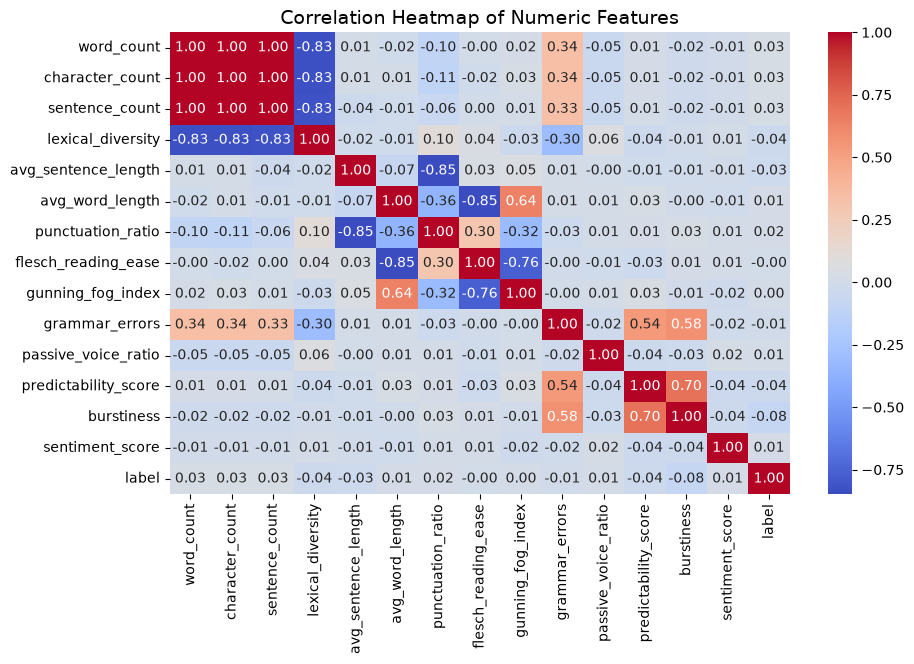

In [35]:
# Ashwin Vinod
# Heatmap
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 6))
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features", fontsize=14)
plt.savefig('heatmap.png')
plt.show()

A **Correlation Heatmap** is used to identify patterns and relationships between multiple features. There is a high inverse relation between the word lengths and the flesch reading ease scores.

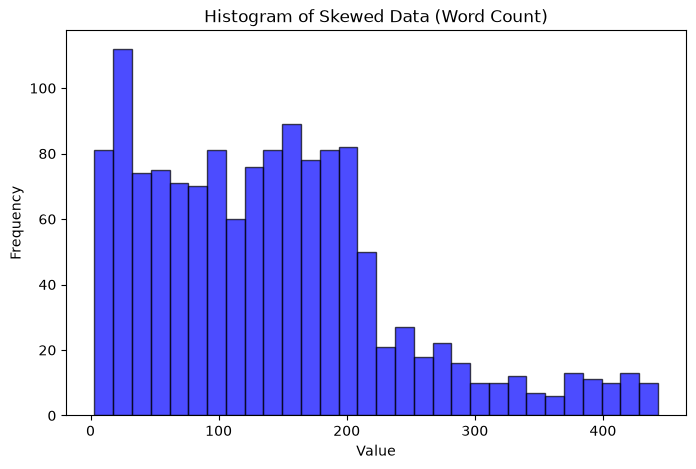

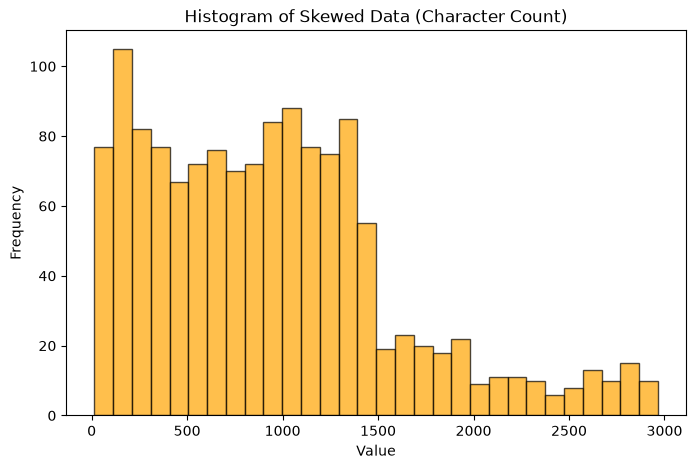

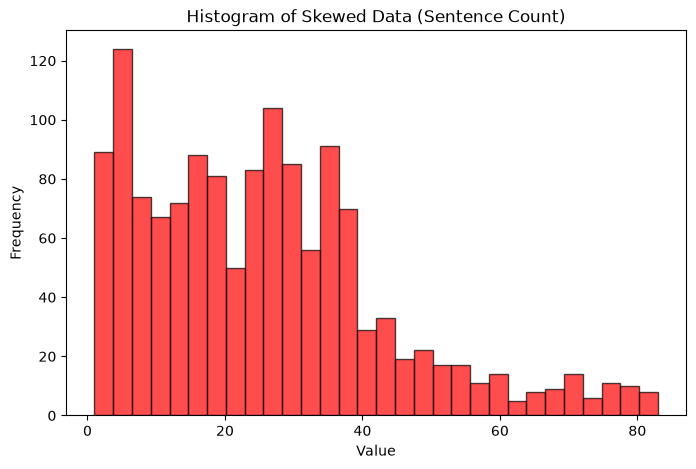

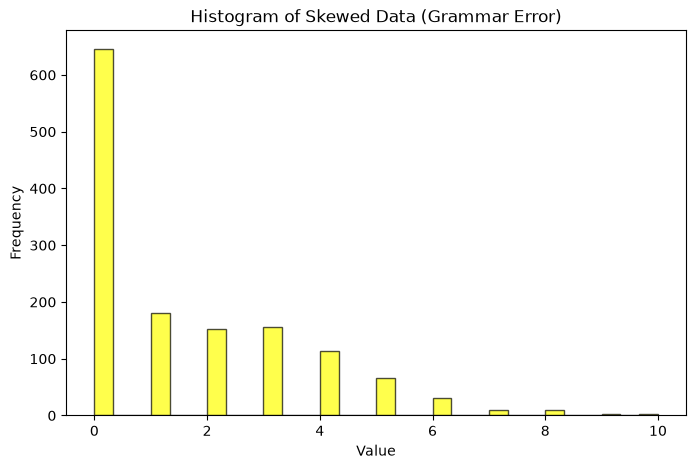

In [36]:
# Logan Caraway
# plotting histograms to show data skew
plt.figure(figsize=(8,5))
plt.hist(df["word_count"], bins=30, color='blue', edgecolor='black', alpha=0.7)
plt.title("Histogram of Skewed Data (Word Count)")
plt.xlabel("Value")
plt.ylabel("Frequency")
#plt.show()
plt.savefig('word-count-hist.png')

plt.figure(figsize=(8,5))
plt.hist(df["character_count"], bins=30, color='orange', edgecolor='black', alpha=0.7)
plt.title("Histogram of Skewed Data (Character Count)")
plt.xlabel("Value")
plt.ylabel("Frequency")
#plt.show()
plt.savefig('char-count-hist.png')

plt.figure(figsize=(8,5))
plt.hist(df["sentence_count"], bins=30, color='red', edgecolor='black', alpha=0.7)
plt.title("Histogram of Skewed Data (Sentence Count)")
plt.xlabel("Value")
plt.ylabel("Frequency")
#plt.show()
plt.savefig('sent-count-hist.png')

plt.figure(figsize=(8,5))
plt.hist(df["grammar_errors"], bins=30, color='yellow', edgecolor='black', alpha=0.7)
plt.title("Histogram of Skewed Data (Grammar Error)")
plt.xlabel("Value")
plt.ylabel("Frequency")
#plt.show()
plt.savefig('gram-err-hist.png')


**Histograms** of skewed data is used to find the skewness of the data. The figures showed that the data is positive or right-skewed. It means that most of the data are smaller values and the mean would be greater than the median.

Changed Sentiment_score Nan values to 0 (Neutral)
Changed burstiness (

In [37]:
# Bella
# This code sets up pandas to display all DataFrame columns and includes a note about a future preprocessing step to correctly apply train-set statistics (like mean and median) to both train and test data.

#df = preprocess(df)            #<------------Future Enchancement: Could call preprocess after split to have values updated to mean and median of train values and then for test values
pd.set_option('display.max_columns', None)  #Helps to print all columns instead of ommiting some as "..."
# df.head()

In [38]:
# Bella Matasic
# This code splits a labeled dataset into balanced training and test sets using scikit-learn, separating features (X) from labels (y) and resetting their indices to keep everything aligned and clean for modeling.
from sklearn.model_selection import train_test_split
import pandas as pd

# Features/labels
X = df.drop(columns=['label'])
y = df['label']            # keep as a Series (fine), or y = df['label'].to_numpy()

# Split (note: returns X_train, X_test, y_train, y_test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # keep class balance; drop this if you don't want stratification
)

# Ensure aligned, 0..n-1 indices
X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

In [39]:
# Alyssa Quijano - helped bella test out other base solutions like logistic regression but it performed worse than code below

# Bella Matasic
# This code builds and trains a text classification pipeline that converts text into TF-IDF features and feeds them into a linear SVM model, then evaluates its accuracy on the test set.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

text_col = "text_content"

# Text-only preprocessing
preprocess = ColumnTransformer(
    [("text", TfidfVectorizer(
        ngram_range=(1,2),
        sublinear_tf=True,
        max_features=200_000
    ), text_col)],
    remainder="drop"
)

# Final optimized model
svm_clf = Pipeline([
    ("prep", preprocess),
    ("clf", LinearSVC(C=1.0))
])

svm_clf.fit(X_train, y_train)
y_pred = svm_clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Final LinearSVC Accuracy: {acc:.4f}")

tfidf = svm_clf.named_steps["prep"].named_transformers_["text"]
feature_names = tfidf.get_feature_names_out()
print(len(feature_names))


Final LinearSVC Accuracy: 0.5912
141442


In [40]:
import json
import numpy as np

# 1. Extract vectorizer & LinearSVC parameters from your fitted pipeline
tfidf = svm_clf.named_steps["prep"].named_transformers_["text"]
clf = svm_clf.named_steps["clf"]

vocab = tfidf.vocabulary_          # {term: index}
idf = tfidf.idf_                   # array of shape (n_features,)
coef = clf.coef_[0]                # array of shape (n_features,)
intercept = float(clf.intercept_[0])

# Keep the top 25,000 most influential n-grams by |coef| so the file is fast & < 2MB for GitHub Pages
top_k = 25000
top_indices = np.argsort(np.abs(coef))[-top_k:]
top_set = set(top_indices.tolist())

weights_dict = {}
for term, idx in vocab.items():
    if idx in top_set:
        # Store [idf, coef] rounded to 5 decimals
        weights_dict[term] = [round(float(idf[idx]), 5), round(float(coef[idx]), 5)]

model_export = {
    "intercept": round(intercept, 6),
    "weights": weights_dict
}

# Save as a JS file so it works both locally (file://) and on GitHub Pages without CORS issues
with open("model_weights.js", "w", encoding="utf-8") as f:
    f.write("window.TEXT_MODEL = ")
    json.dump(model_export, f, separators=(",", ":"))
    f.write(";")

print(f"Exported {len(weights_dict)} features to model_weights.js")

Exported 25000 features to model_weights.js


In [44]:
import nbformat
from nbconvert import HTMLExporter

notebook_filename = "Team 9 Code.ipynb"

# 1. Read the notebook and strip broken Colab/Kaggle widget metadata
with open(notebook_filename, "r", encoding="utf-8") as f:
    nb = nbformat.read(f, as_version=4)

if "widgets" in nb.metadata:
    del nb.metadata["widgets"]

for cell in nb.cells:
    if "outputs" in cell:
        for output in cell["outputs"]:
            if "data" in output and "application/vnd.jupyter.widget-view+json" in output["data"]:
                del output["data"]["application/vnd.jupyter.widget-view+json"]

# 2. Convert cleanly to HTML
html_exporter = HTMLExporter()
body, _ = html_exporter.from_notebook_node(nb)

with open("notebook.html", "w", encoding="utf-8") as f:
    f.write(body)

print("Successfully exported notebook.html!")

Successfully exported notebook.html!
